# Quantification et génération FPGA

Un seul notebook pilote désormais la quantification, la simulation arithmétique bit-exacte, les fichiers mémoire et le RTL. Pour changer de plateforme, modifiez uniquement `target` et `architecture` dans la configuration.

In [8]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

# Renseignez ce chemin uniquement si Jupyter est lancé hors du dépôt.
PROJECT_ROOT_OVERRIDE = None  # Exemple : Path('/chemin/vers/RECIPE_MLP_FPGA')

candidates = [PROJECT_ROOT_OVERRIDE] if PROJECT_ROOT_OVERRIDE else []
candidates += [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path.resolve() for path in candidates if path and (path / 'src' / 'py' / 'fpga_targets.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError(
        'Racine introuvable : renseignez PROJECT_ROOT_OVERRIDE avec le dossier du dépôt.'
    )

source_dir = PROJECT_ROOT / 'src' / 'py'
if str(source_dir) not in sys.path:
    sys.path.insert(0, str(source_dir))

from quantization import (
    TARGET_PROFILES,
    run_quantization,
    validate_quantization_config,
)

## Configuration unique

Choix disponibles :

- `target`: `ultra96` (AXI-Stream, DSP 48 bits) ou `lattice` (UART, DSP 32 bits) ;
- `architecture`: `sequential` ou `pipeline`.

In [9]:
config = {
    'name': 'leaky_relu',
    'model_path': 'data/walter/mlp_walter.pt',
    'dataset_path': 'data/walter/dataset_walter.npz',
    'output_root': 'data/quantized_data',

    'target': 'ultra96',             # ultra96 or lattice
    'architecture': 'sequential',    # sequential or pipeline
    'device': 'cpu',

    'weight_bits': 16,
    'bias_bits': 16,
    'act_bits': 16,
    #'dsp_bits': 48,
    'margin_weights': 0.0,
    'margin_acts': 0.0,
    'calibration_mode': 'max',       # max or percentile
    'calibration_percentile': 99.9,
    'activation_negative_slope': 1 / 64,

    'dsp_acc_max_utilization': 0.90,
    'dsp_weight_search_max_steps': 24,

    'lut_addr_bits_min': 3,
    'lut_addr_bits_max_cap': 9,
    'lut_max_words': 1024,
    'lut_auto_window': 2,
    'activation_score_memory_weight': 0.03,

    'test_samples': 100,
    'simulation_samples': None,      # None = toute la base
    'fail_on_overflow': True,
    'generate_report': True,
    'generate_rtl': True,
}

config = validate_quantization_config(config)
TARGET_PROFILES[config['target']]

TargetProfile(name='ultra96', transport='axi_stream', dsp_bits=48, toolchain='vivado', device='xczu3eg-sbva484-1-e', executables=('vivado',))

## Exécution complète

Cette cellule calibre les échelles, protège le DSP, sélectionne les LUT, exporte les mémoires, simule le datapath de la carte et génère le RTL correspondant.


BASIC QUANTIZATION
Model path       : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/walter/mlp_walter.pt
Dataset path     : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/walter/dataset_walter.npz
Output directory : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/quantized_data/leaky_relu/ultra96/sequential
FPGA export mode : sequential
ACT_W / DSP_PW   : 16 / 48
Number of layers : 6


,layer,is_output,w_shape,input_exp,weight_exp,bias_exp,preact_exp,act_exp,output_exp,activation
0,layer_0,False,"(66, 6)",16,15,18,16.0,17.0,NaN,leaky_relu
1,layer_1,False,"(50, 66)",17,14,18,16.0,16.0,NaN,leaky_relu
2,layer_2,False,"(38, 50)",16,14,18,15.0,16.0,NaN,leaky_relu
3,layer_3,False,"(28, 38)",16,14,18,15.0,15.0,NaN,leaky_relu
4,layer_4,False,"(20, 28)",15,14,18,15.0,15.0,NaN,leaky_relu
5,layer_5,True,"(2, 20)",15,15,19,NaN,NaN,15.0,-



DSP-AWARE WEIGHT SCALE OPTIMIZATION -- FLOAT CALIBRATION
DSP_PW                  : 48 bits
Allowed utilization     : 90.0%
Calibration source      : original FLOAT tensors, independently per layer
Scale modified          : SW only, independently for each layer
Stored weights          : re-quantized from W_float at each SW_selected
Report CSV              : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/quantized_data/leaky_relu/ultra96/sequential/dsp_accumulator_report.csv


,layer,is_output,calibration_domain,sx,sb,sw_initial,sw_selected,sw_bits_lost,s_acc_selected,dsp_bits,...,dsp_safe_real_min,dsp_safe_real_max,dsp_utilization_%,safe_window_utilization_%,worst_value_float,worst_sample,worst_neuron,worst_mac_index,worst_sign,candidate_attempts
0,layer_0,False,float,16,18,15,15,0,31,48,...,-58982.4,58982.4,0.000483,0.000536,-0.316439,395,0,4,negative,1
1,layer_1,False,float,17,18,14,14,0,31,48,...,-58982.4,58982.4,0.000671,0.000746,-0.439808,319,25,60,negative,1
2,layer_2,False,float,16,18,14,14,0,30,48,...,-117964.8,117964.8,0.000572,0.000635,-0.749467,2608,14,43,negative,1
3,layer_3,False,float,16,18,14,14,0,30,48,...,-117964.8,117964.8,0.000525,0.000583,0.687553,289,17,27,positive,1
4,layer_4,False,float,15,18,14,14,0,29,48,...,-235929.6,235929.6,0.000305,0.000339,0.800009,1113,13,27,positive,1
5,layer_5,True,float,15,19,15,15,0,30,48,...,-117964.8,117964.8,0.000472,0.000525,-0.619247,85,0,19,negative,1


,layer_name,activation_name,implementation,addr_bits,input_exp,output_exp,mae,max_abs_err,mae_lsb_out,max_abs_err_lsb_out,...,mae_normalized,memory_bits_normalized,score,touch_last_segment,touch_count,touch_ratio,headroom_q,max_pre_q,max_safe_q,is_best
0,layer_0,leaky_relu,analytic_int,None,16,17,0.000006,0.000015,0.737418,2.0,...,NaN,NaN,NaN,False,0,0.0,NaN,11574,NaN,True
1,layer_1,leaky_relu,analytic_int,None,16,16,0.000006,0.000015,0.240566,1.0,...,NaN,NaN,NaN,False,0,0.0,NaN,20614,NaN,True
2,layer_2,leaky_relu,analytic_int,None,15,16,0.000012,0.000030,0.770765,2.0,...,NaN,NaN,NaN,False,0,0.0,NaN,15113,NaN,True
3,layer_3,leaky_relu,analytic_int,None,15,15,0.000011,0.000030,0.237825,1.0,...,NaN,NaN,NaN,False,0,0.0,NaN,21605,NaN,True
4,layer_4,leaky_relu,analytic_int,None,15,15,0.000011,0.000030,0.255015,1.0,...,NaN,NaN,NaN,False,0,0.0,NaN,26215,NaN,True



FINAL EXPORT OF CONCATENATED .MEM ARTIFACTS
Export directory      : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/quantized_data/leaky_relu/ultra96/sequential
Verilog header      : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/quantized_data/leaky_relu/ultra96/sequential/scales.vh
.mem files       :
- weights             : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/quantized_data/leaky_relu/ultra96/sequential/weight_all.mem (7260 words)
- biases             : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/quantized_data/leaky_relu/ultra96/sequential/bias_all.mem (204 words)
- LUT activations   : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/quantized_data/leaky_relu/ultra96/sequential/act_all.mem (0 words)
Layout debug        : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/quantized_data/leaky_relu/ultra96/sequential/mem_layout.json

Weight/bias layout :
- layer_0 | W offset=0 len=396 shape=(66, 6) | B offset=0 len=66
- layer_1 | W offset=396 len=3300 shape=(

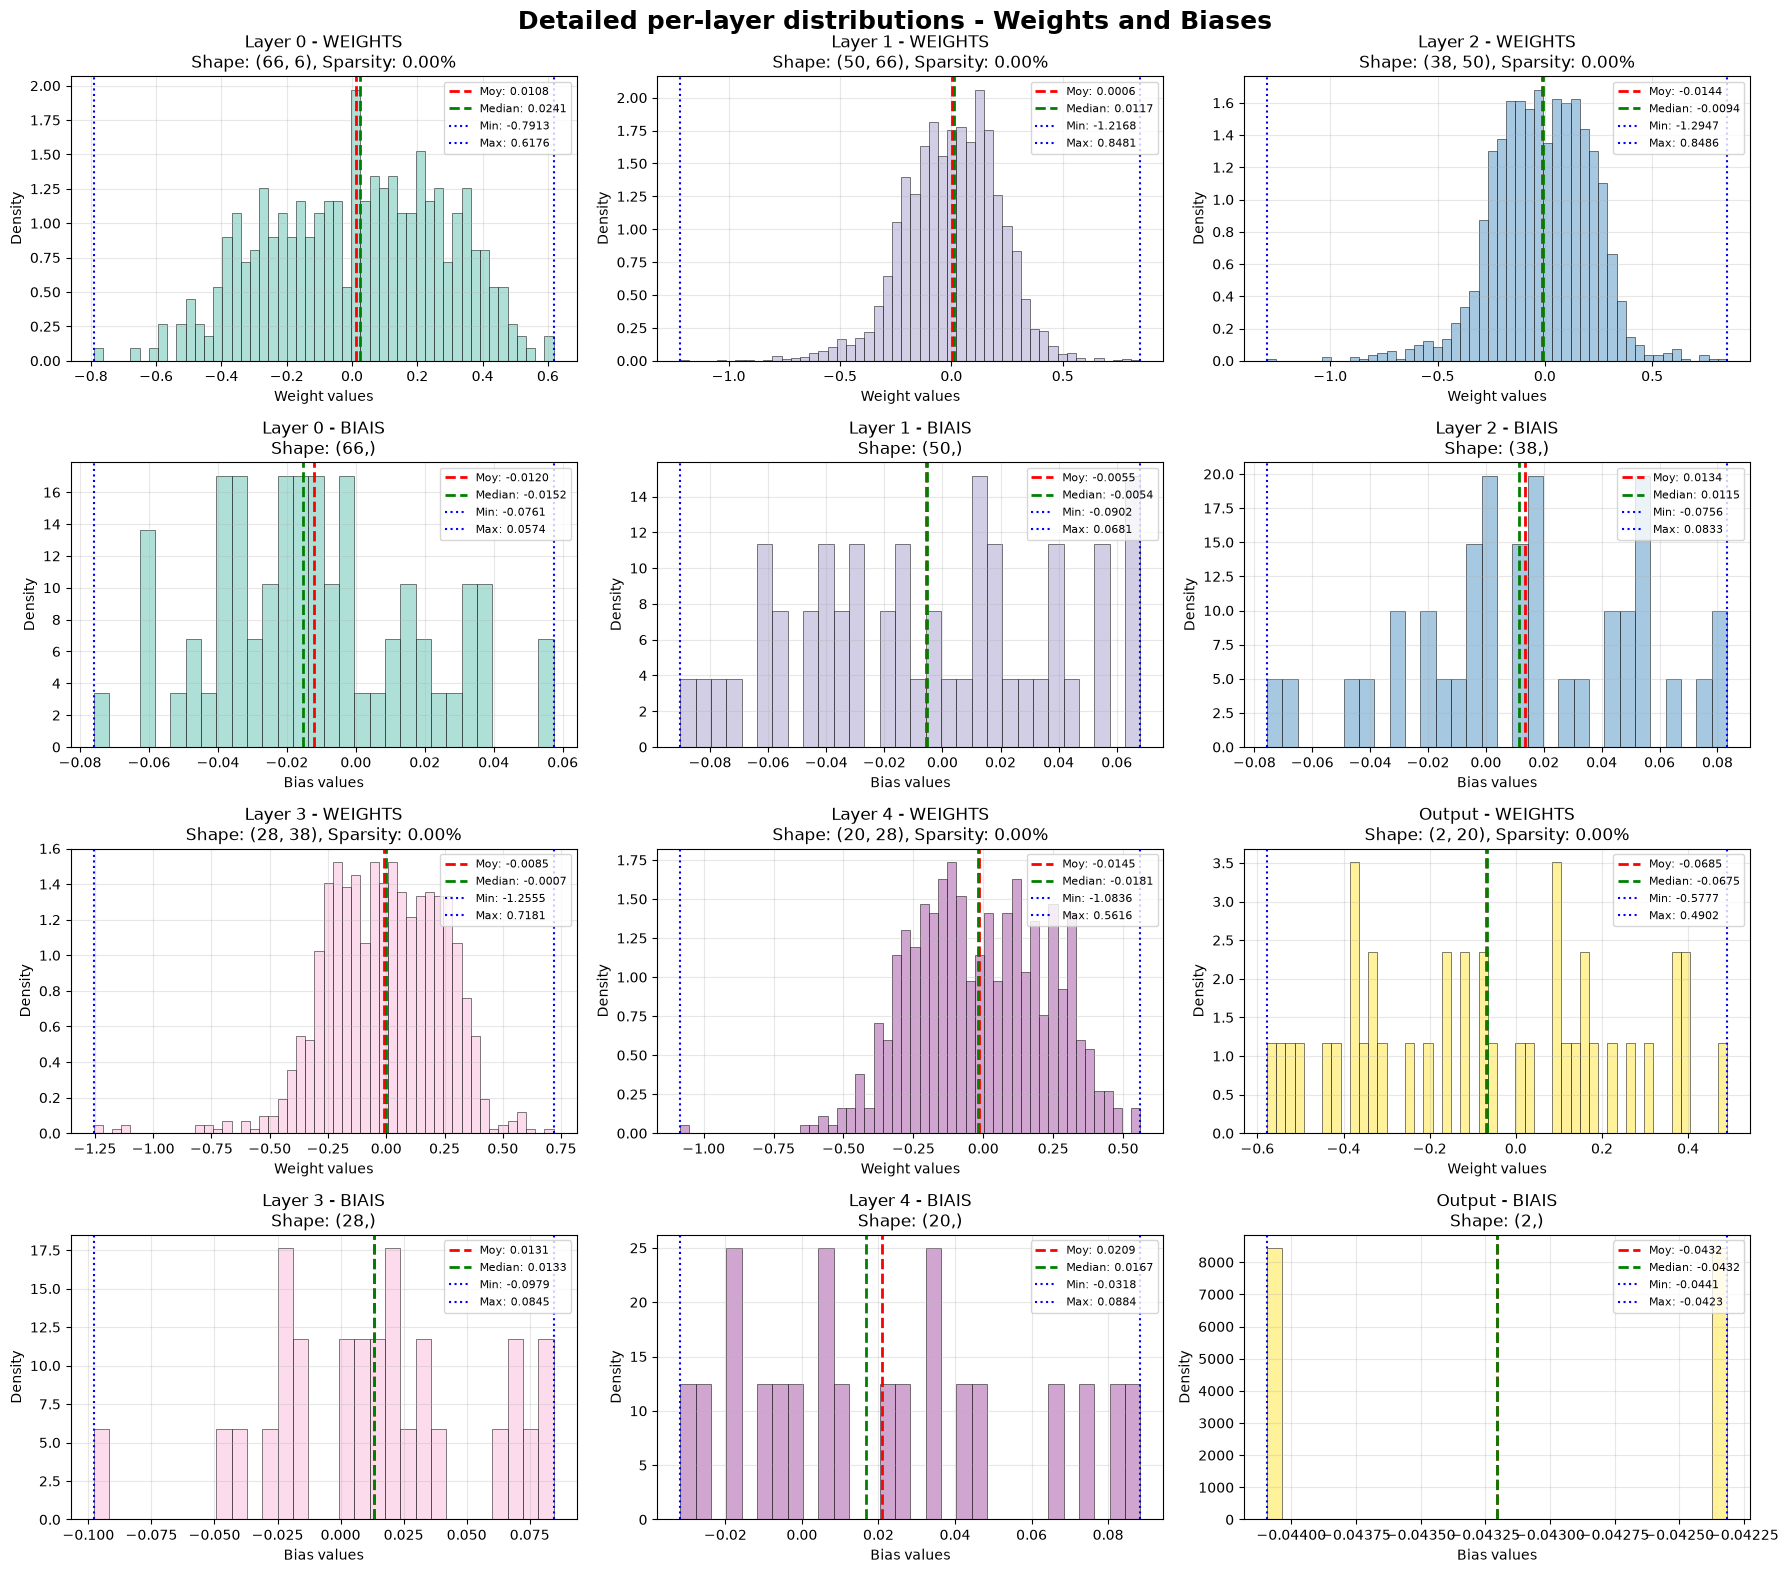

✅ Per-layer distribution plots generated


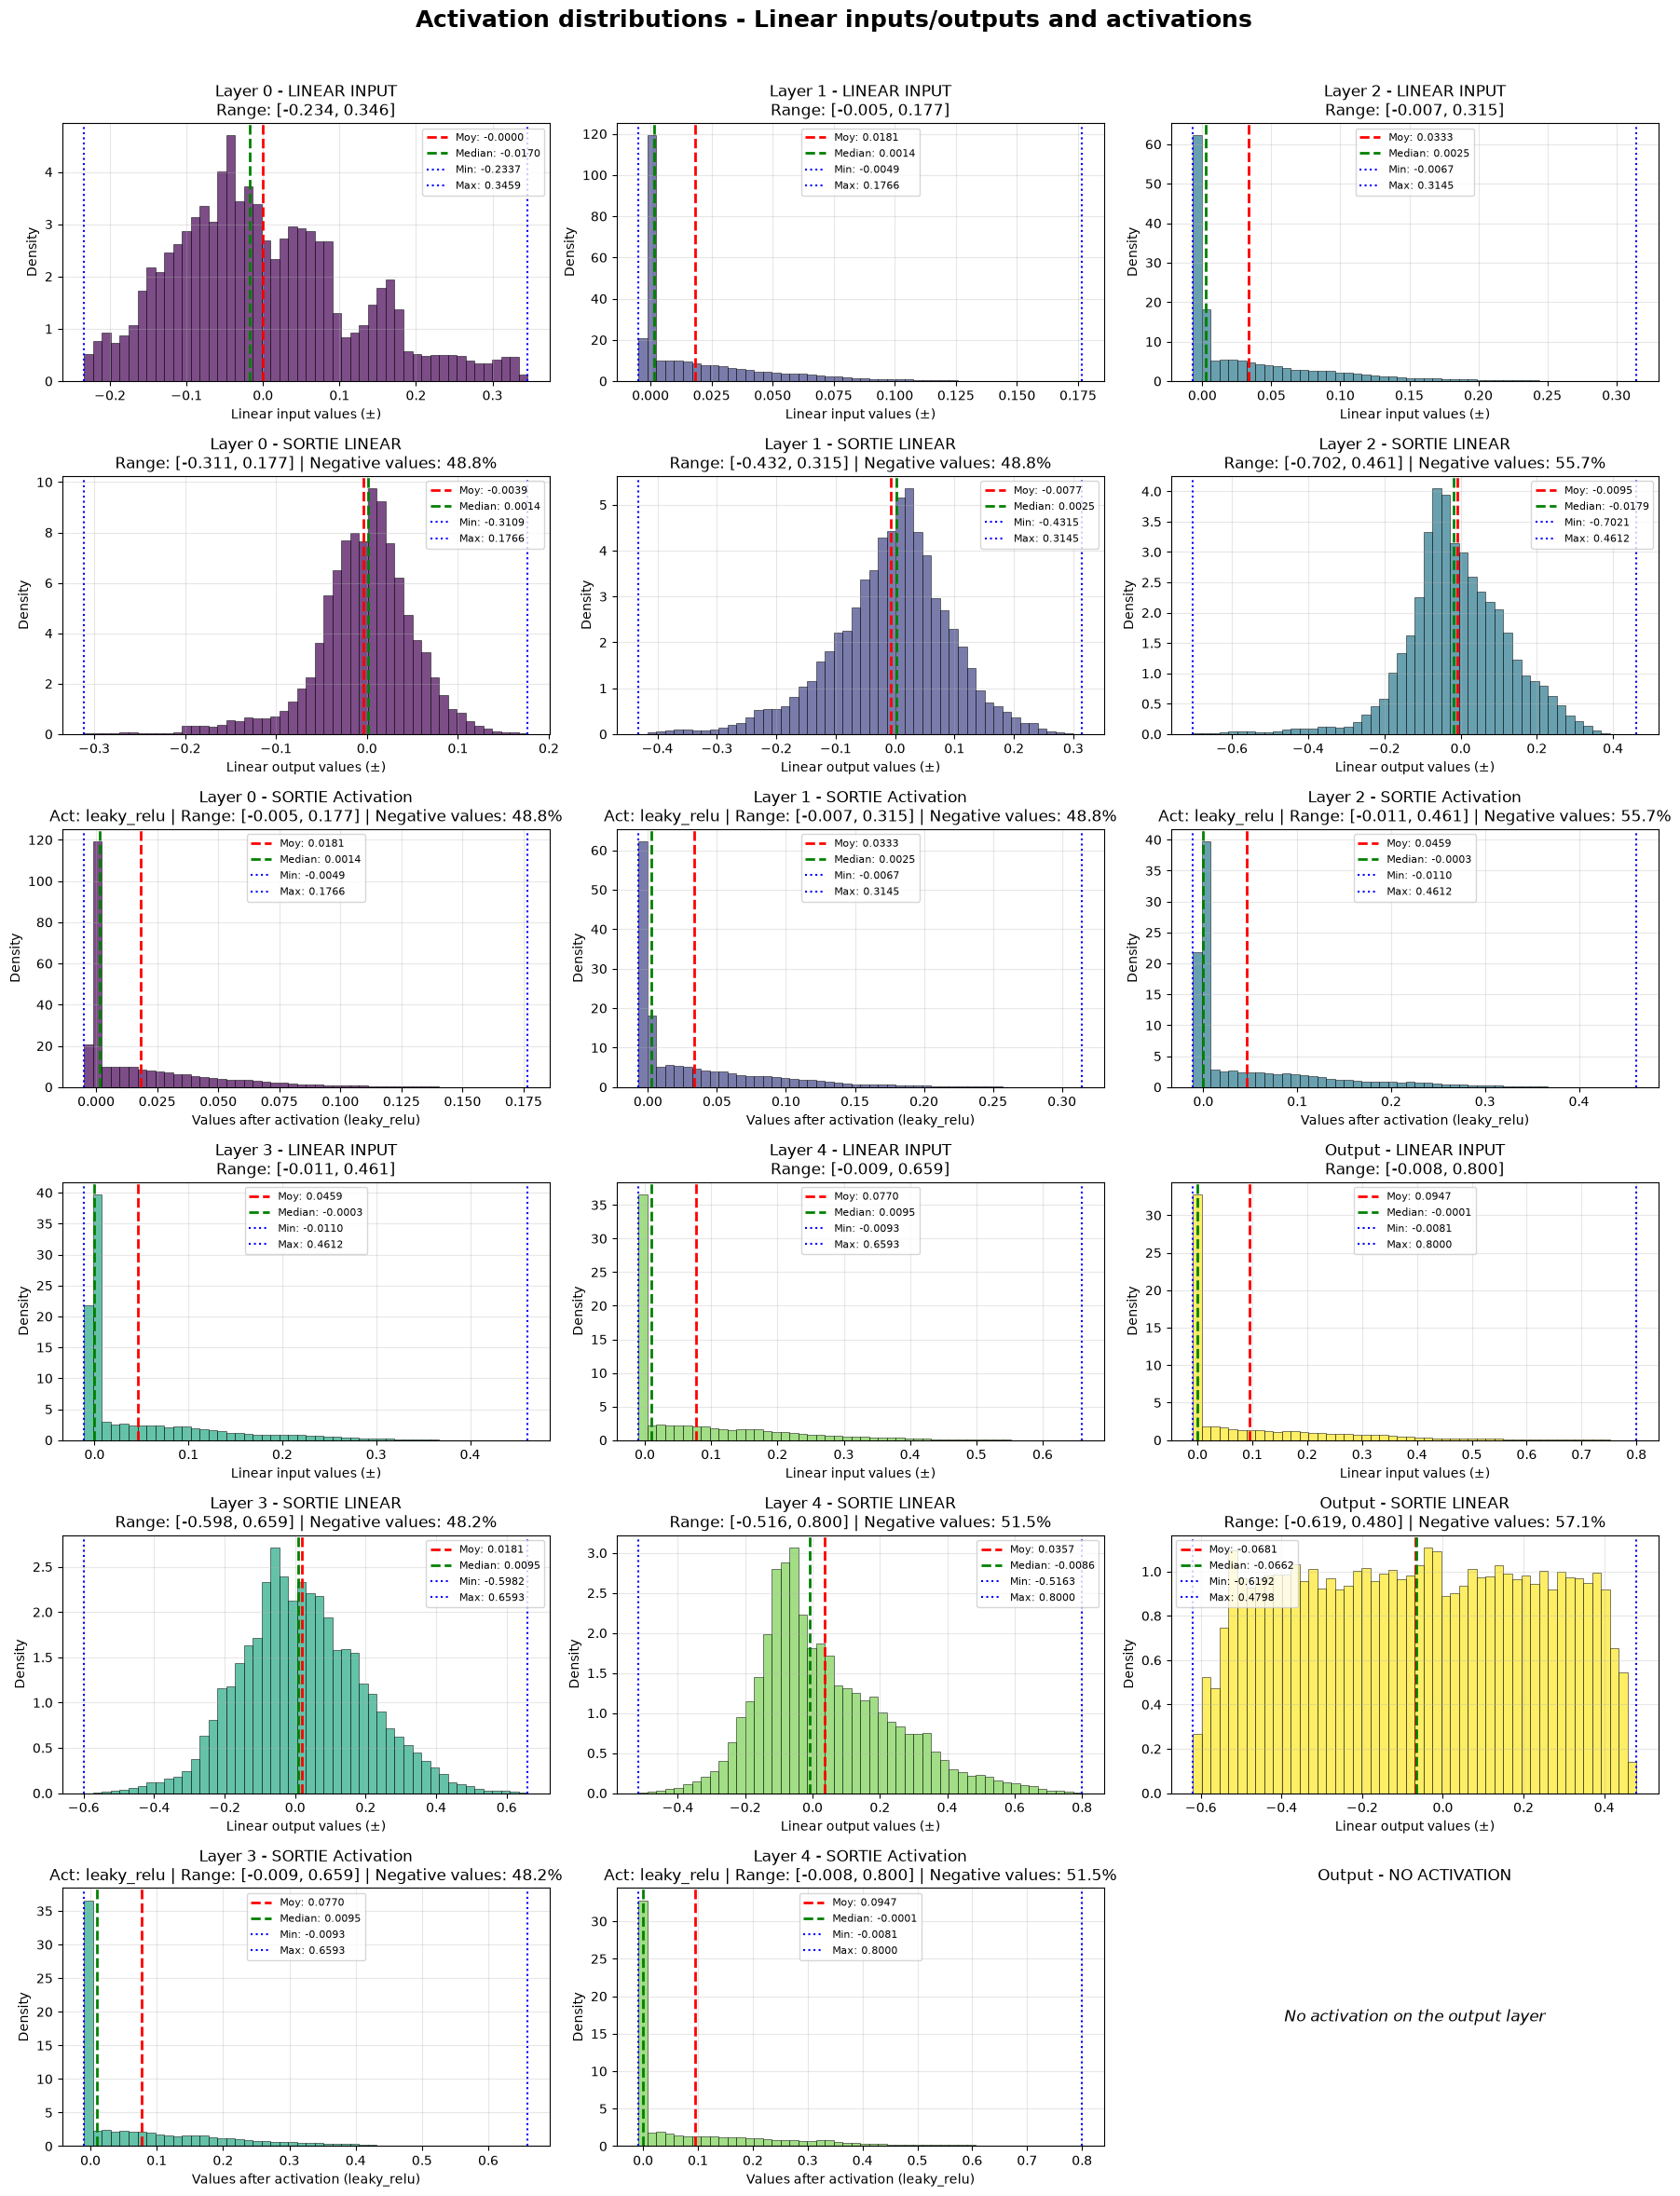

✅ Activation distribution plots generated


,tensor,layer,kind,activation,implementation,selected_N,shift_exponent,scale_factor,bits,float32_min,float32_max,int_min,int_max,utilisation_sym_%
0,input,-,input,-,-,-,16,65536,16,-0.233695,0.345871,-15315,22667,69.2%
1,layer_0_weights,layer_0,weights,-,-,-,15,32768,16,-0.791346,0.617584,-25931,20237,79.1%
2,layer_0_bias,layer_0,bias,-,-,-,18,262144,16,-0.076065,0.057380,-19940,15042,60.9%
3,layer_0_preact,layer_0,preact,leaky_relu,analytic_int,-,16,65536,16,-0.310882,0.176613,-20374,11574,62.2%
4,layer_0_act,layer_0,act,leaky_relu,analytic_int,-,17,131072,16,-0.004858,0.176613,-637,23149,70.6%
5,layer_1_weights,layer_1,weights,-,-,-,14,16384,16,-1.216827,0.848078,-19936,13895,60.8%
6,layer_1_bias,layer_1,bias,-,-,-,18,262144,16,-0.090225,0.068105,-23652,17853,72.2%
7,layer_1_preact,layer_1,preact,leaky_relu,analytic_int,-,16,65536,16,-0.431540,0.314545,-28281,20614,86.3%
8,layer_1_act,layer_1,act,leaky_relu,analytic_int,-,16,65536,16,-0.006743,0.314545,-442,20614,62.9%
9,layer_2_weights,layer_2,weights,-,-,-,14,16384,16,-1.294705,0.848567,-21212,13903,64.7%


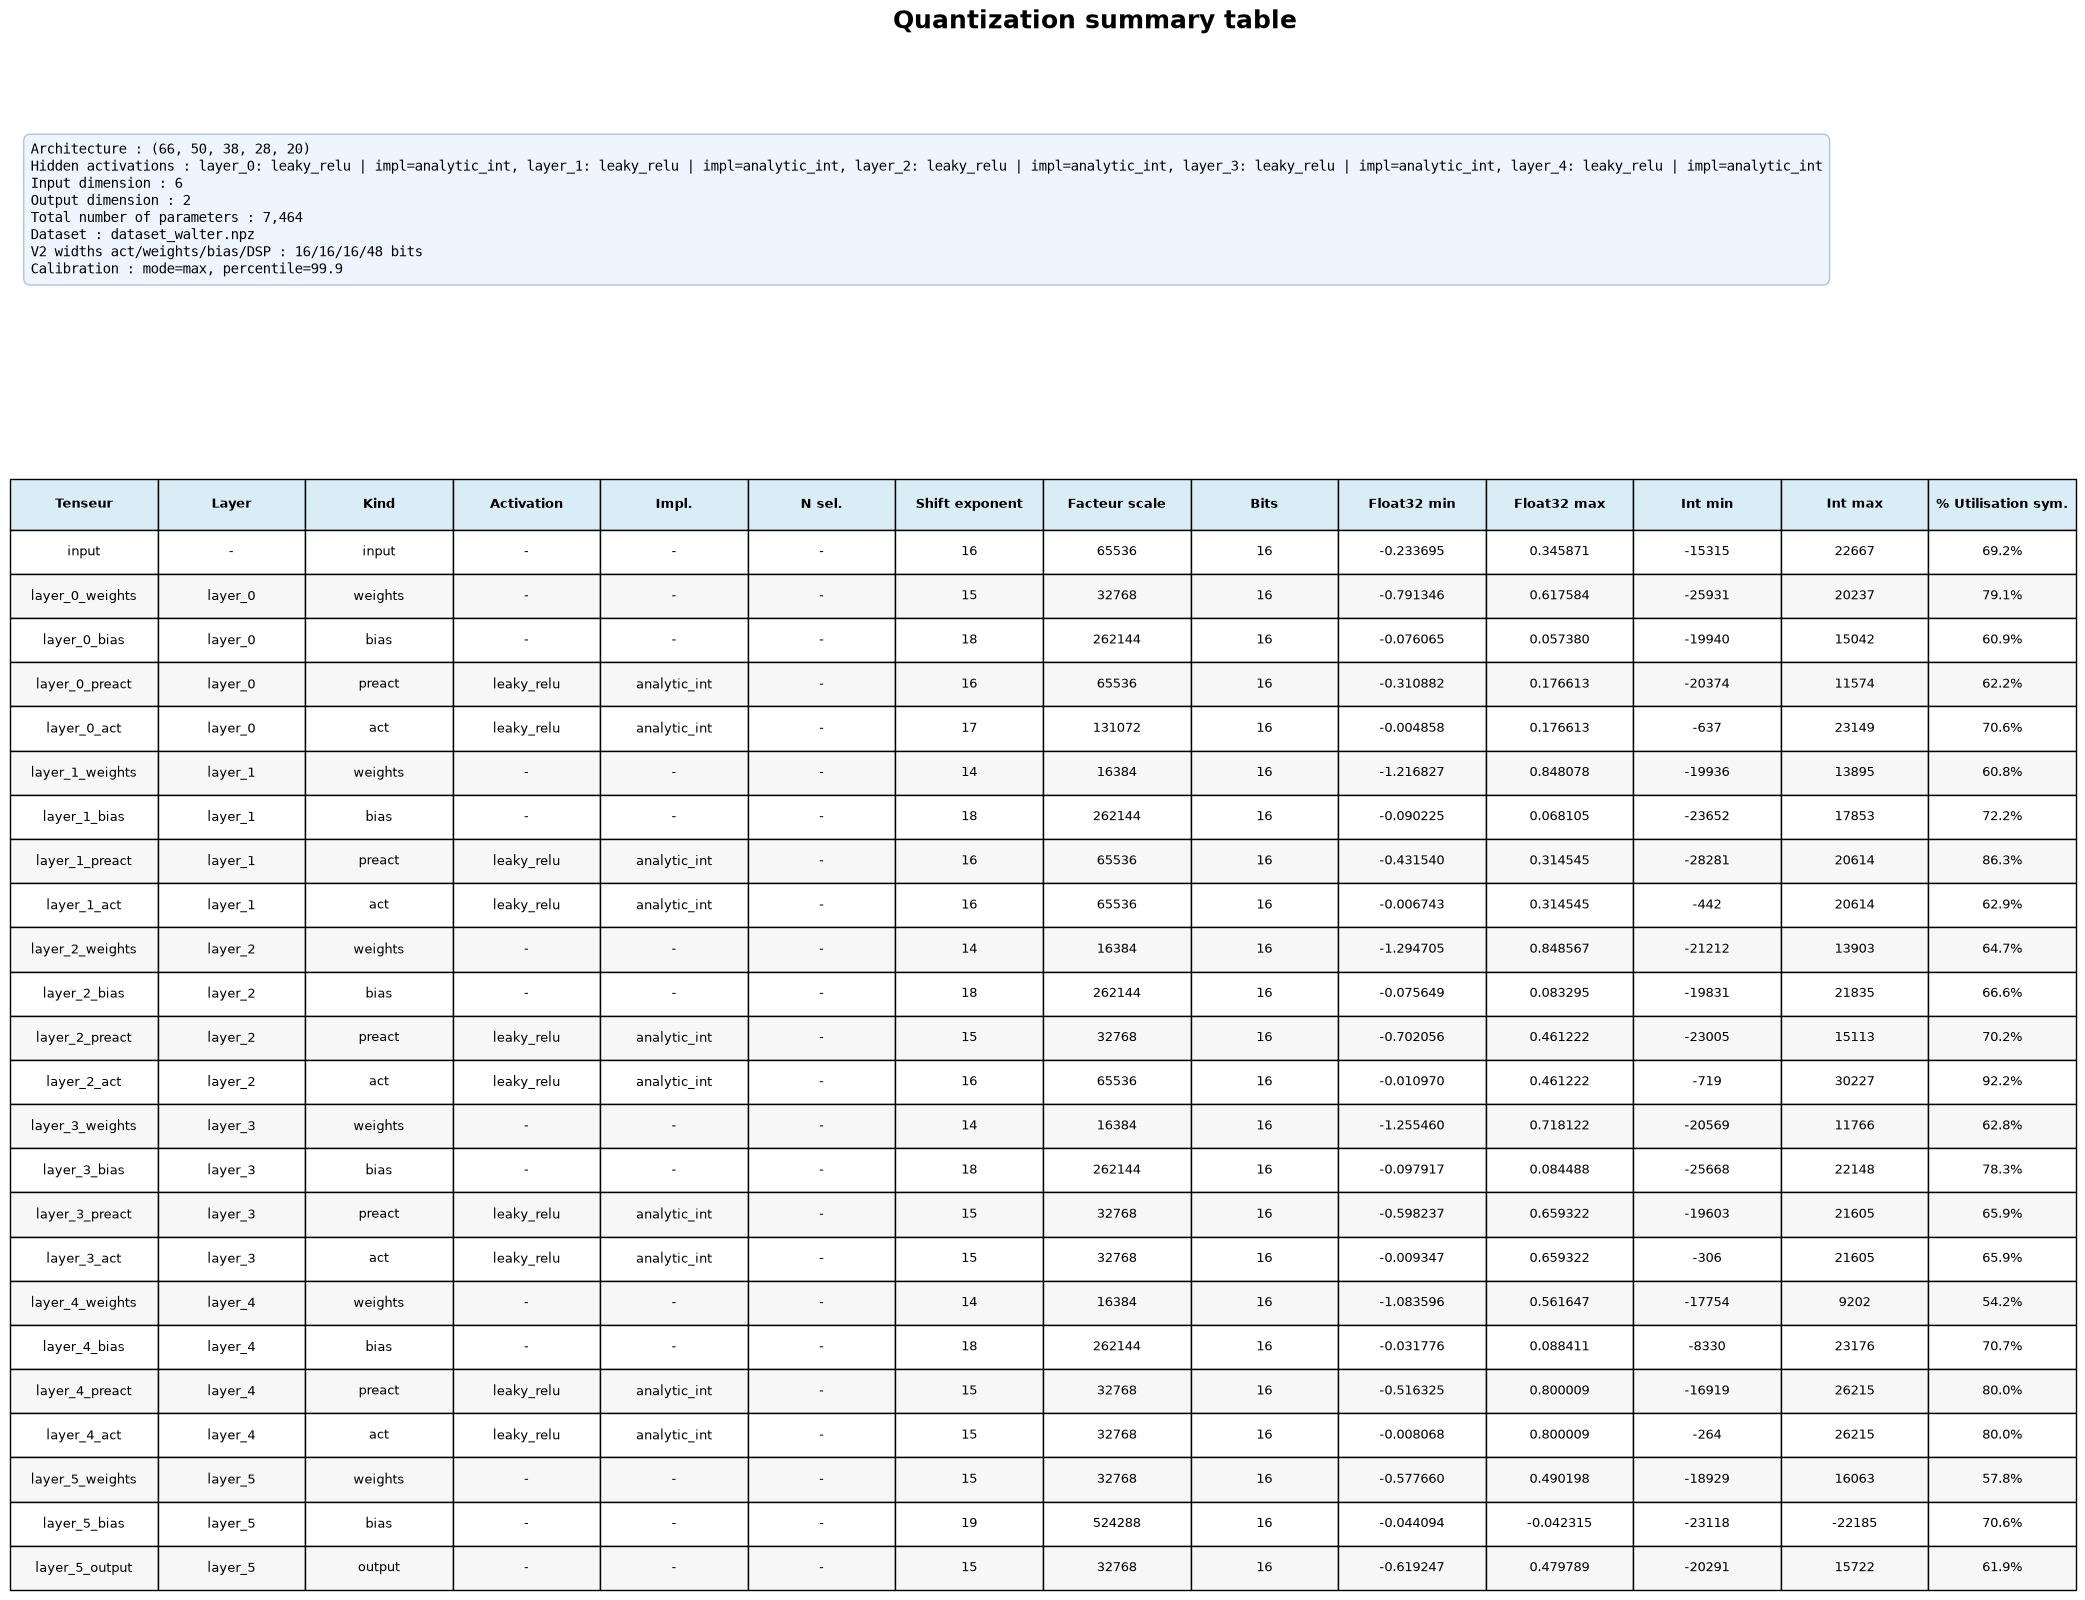

✅ Quantization summary table generated
✅ PDF exported : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/quantized_data/leaky_relu/ultra96/sequential/distribution_analysis_report.pdf

QUANTIZATION COMPLETE
Target / mode : ultra96 / sequential
DSP / transport: 48 bits / axi_stream
Output          : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/quantized_data/leaky_relu/ultra96/sequential
FPGA overflows  : 0
Board vs float  : 0.006349 deg mean


In [10]:
run = run_quantization(config, project_root=PROJECT_ROOT)

## Résultats de la simulation FPGA

In [11]:
pd.Series(run.simulation_summary, name='value').to_frame()

,value
samples,13640
target,ultra96
architecture,sequential
transport,axi_stream
dsp_bits,48
input_exp,16
output_exp,15
overflow_count,0
exact_output_words_vs_float_quantized,4605
total_output_words,27280


In [12]:
run.simulation_report

,layer,layer_index,input_exp,weight_exp,bias_exp,accumulator_exp,accumulator_min,accumulator_max,bias_wrap_count,product_wrap_count,accumulator_wrap_count,preactivation_exp,preactivation_shift_wrap_count,activation_shift_wrap_count,output_narrowing_count,output_exp,output_min,output_max,overflow_count
0,layer_0,0,16,15,18,31,-667628792,379270495,0,0,0,16.0,0.0,0,0,17,-638,23148,0
1,layer_1,1,17,14,18,31,-926728548,675507526,0,0,0,16.0,0.0,0,0,16,-442,20614,0
2,layer_2,2,16,14,18,30,-753617863,495208225,0,0,0,15.0,0.0,0,0,16,-720,30224,0
3,layer_3,3,16,14,18,30,-642350906,707965380,0,0,0,15.0,0.0,0,0,15,-307,21605,0
4,layer_4,4,15,14,18,29,-277191789,429535970,0,0,0,15.0,0.0,0,0,15,-265,26216,0
5,layer_5,5,15,15,19,30,-664952776,515212795,0,0,0,NaN,NaN,0,0,15,-20293,15723,0


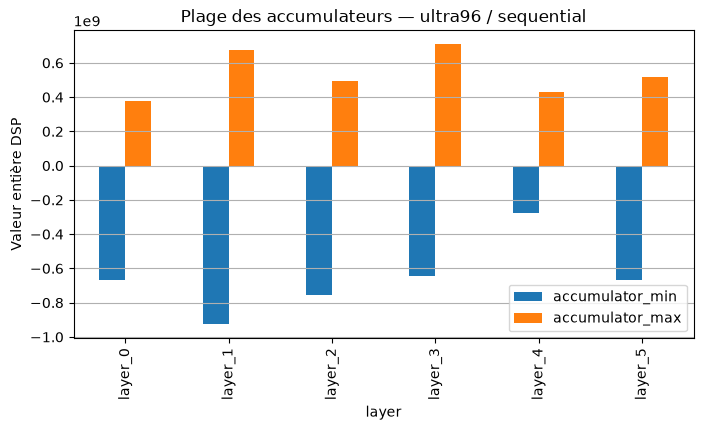

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
run.simulation_report.plot(
    x='layer',
    y=['accumulator_min', 'accumulator_max'],
    kind='bar',
    ax=ax,
)
ax.set_title(f"Plage des accumulateurs — {config['target']} / {config['architecture']}")
ax.set_ylabel('Valeur entière DSP')
ax.grid(True, axis='y')
plt.show()

## Artefacts

Le manifeste ci-dessous référence la configuration, les mémoires, le dataset quantifié, les vecteurs de testbench, le rapport de simulation et le RTL généré.

In [14]:
print(f'Manifeste : {run.manifest_path}')
print(f'Dataset quantifié : {run.dataset_path}')
if run.rtl_project:
    print(f"RTL : {run.rtl_project['generated_rtl_dir']}")

Manifeste : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/quantized_data/leaky_relu/ultra96/sequential/quantization_manifest.json
Dataset quantifié : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/quantized_data/leaky_relu/ultra96/sequential/dataset_walter_quantized.npz
RTL : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/src/rtl/generated/src_ultra_sequential
